Matplotlib is building the font cache; this may take a moment.


[[477.77065181 499.42910319 502.48456774 ... 495.08021343 526.05147675
  552.05703513]
 [473.34548611 493.26445512 506.06910408 ... 500.5974668  525.65870468
  549.60443951]
 [449.39878297 469.15552936 489.60856372 ... 502.69194764 518.70783806
  533.25775177]
 ...
 [514.58325674 503.07006946 496.09669277 ... 467.34148811 456.50572253
  445.80469809]
 [498.82562394 475.00505639 460.75998145 ... 449.34332073 429.2045263
  414.35862478]
 [482.25083734 448.52757523 435.81587993 ... 428.67398331 402.29491934
  380.5024775 ]]


NameError: name 'X' is not defined

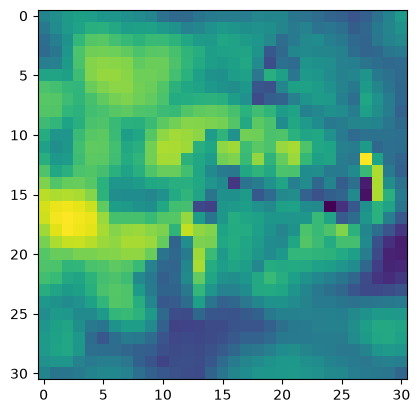

In [1]:

from matplotlib import pyplot as plt
from PIL import Image
import matplotlib.image as img
import numpy as np


sizexy=64
image = img.imread("dataset/NotRobin/NotRobin1.jpg")
Greyscale = np.mean(image[:, :, :3], axis=2)
Greyscale = np.array(Image.fromarray(Greyscale).resize((sizexy, sizexy)))
plt.imshow(Greyscale,interpolation='nearest')

n=3
ans_xy=(sizexy-n+1)
#Convo_arr=[1,0,-1,1,0,-1,1,0,-1]#verticle
kernel = np.random.randn(3,3)


ans=np.zeros((ans_xy,ans_xy))
i=0
j=0
Total=0
c=0
for k in range(ans_xy):
    for c in range(ans_xy):
        Total=0
        for i in range(n):
            for j in range(n) :
                temp=Greyscale[k+i][c+j]*kernel[i][j]
                Total+=temp
                #print (temp)
        
        
        ans[k][c]=Total

plt.imshow(ans,interpolation='nearest')

print (ans)



i=0
j=0
for i in range(len(ans)):
    for j in range(len(ans)) :
       if(ans[i][j]<0):
           ans[i][j]*=0.01
       
plt.imshow(ans,interpolation='nearest')

#pool

pool = 2#int(ans_xy/2)

pooled=np.zeros((int(ans_xy/2),int(ans_xy/2)))
#filter 2*2
#2,2
i=0
j=0
c=0
k=0

biggest=0
for i in range(0, ans_xy-1, 2):
    for j in range(0, ans_xy-1, 2):
        
        biggest=ans[i][j]
        if (biggest<ans[i+1][j]):
            biggest=ans[i+1][j]
        if(biggest<ans[i][j+1]):
            biggest=ans[i][j+1]
        if(biggest<ans[i+1][j+1]):
            biggest=ans[i+1][j+1]
         
        
        pooled[int(i/2)][int(j/2)]=biggest
plt.imshow(pooled,interpolation='nearest')


#dense

dense=pooled.flatten()

import numpy as np

input_size = len(dense)
output_size = 32  

standard_deviation = np.sqrt(2.0 / input_size)
weights = np.random.randn(input_size, output_size) * standard_deviation

biases = np.zeros((1, output_size))
# 1. Calculate the gradient for the weights
d_weights = np.dot(X.T, d_activated)
d_biases = np.sum(d_activated, axis=0, keepdims=True)

# 2. Update the weights (Gradient Descent)
learning_rate = 0.01
weights = weights - (learning_rate * d_weights)
biases = biases - (learning_rate * d_biases)